# Model Evaluation

This notebook evaluates the final trained CNN model on the held-out test set. It generates the figures, tables, and metrics required for the Results and Analysis chapter.

## 1. Imports and Configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)

sns.set_theme(style="whitegrid")

2026-05-16 08:14:17.888785: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-16 08:14:17.890776: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-16 08:14:17.918337: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-16 08:14:17.918356: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-16 08:14:17.919330: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

## 2. Paths and Constants

In [2]:
MODEL_NAME = "malariaNet-ep-10-fc-64-do-0.25-bs-32-test_acc-95.61"
IMAGE_SIZE = (130, 130)
BATCH_SIZE = 32

MODEL_PATH = Path("/models") / f"{MODEL_NAME}.keras"
HISTORY_PATH = Path("/models") / f"{MODEL_NAME}.xlsx"
TEST_DIR = Path("/data/cell_images_split/test")
OUTPUT_DIR = Path("evaluation_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model path:", MODEL_PATH)
print("History path:", HISTORY_PATH)
print("Test directory:", TEST_DIR)
print("Output directory:", OUTPUT_DIR.resolve())

Model path: /models/malariaNet-ep-10-fc-64-do-0.25-bs-32-test_acc-95.61.keras
History path: /models/malariaNet-ep-10-fc-64-do-0.25-bs-32-test_acc-95.61.xlsx
Test directory: /data/cell_images_split/test
Output directory: /home/jovyan/work/evaluation_outputs


## 3. Load Model and Training History

In [3]:
metrics = pd.read_excel(HISTORY_PATH)
model = load_model(MODEL_PATH)

metrics

,loss,accuracy,val_loss,val_accuracy
0,0.776291,0.560147,0.496323,0.828012
1,0.263448,0.914452,0.175151,0.944848
2,0.183858,0.943391,0.151921,0.949565
3,0.174573,0.947065,0.160421,0.948476
4,0.161340,0.949515,0.148378,0.949927
5,0.163233,0.948789,0.145806,0.953556
6,0.161433,0.949333,0.148224,0.956459
7,0.155890,0.950240,0.152597,0.952467
8,0.146768,0.952917,0.133793,0.959361
9,0.150687,0.951873,0.138430,0.955007


## 4. Training and Validation Curves

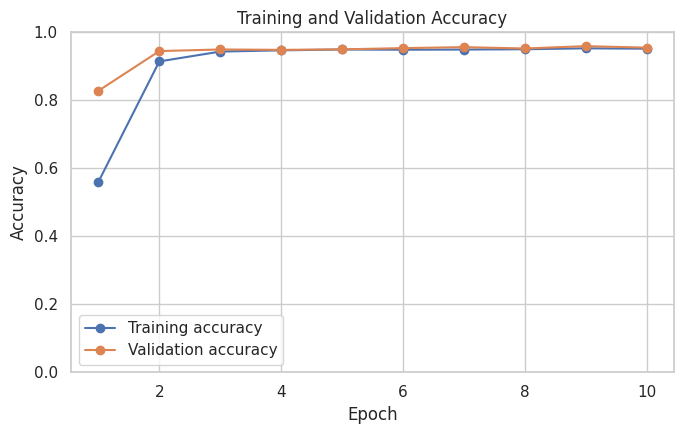

In [4]:
epochs = np.arange(1, len(metrics) + 1)

plt.figure(figsize=(7, 4.5))
plt.plot(epochs, metrics["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs, metrics["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_validation_accuracy.png", dpi=300)
plt.show()

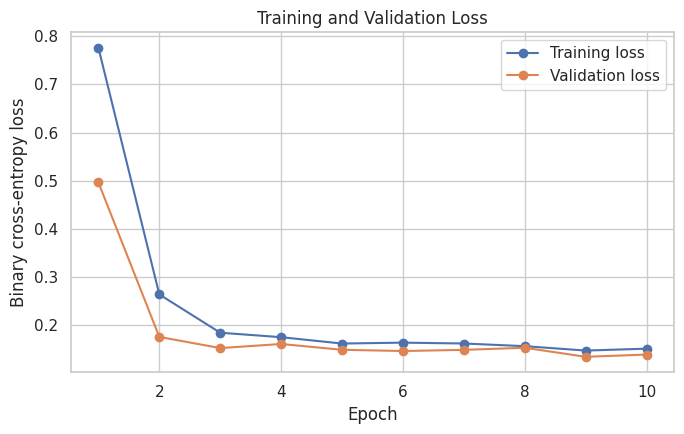

In [5]:
plt.figure(figsize=(7, 4.5))
plt.plot(epochs, metrics["loss"], marker="o", label="Training loss")
plt.plot(epochs, metrics["val_loss"], marker="o", label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_validation_loss.png", dpi=300)
plt.show()

## 5. Load Test Set

In [6]:
test_generator = ImageDataGenerator().flow_from_directory(
    TEST_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    class_mode="binary",
    shuffle=False,
)

class_indices = test_generator.class_indices
index_to_class = {index: label for label, index in class_indices.items()}

print("Class indices:", class_indices)
print("Test images:", test_generator.samples)

Found 2756 images belonging to 2 classes.
Class indices: {'parasitized': 0, 'uninfected': 1}
Test images: 2756


## 6. Evaluate Model on Test Set

In [7]:
test_generator.reset()
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

87/87 [==============================] - 10s 114ms/step - loss: 0.1346 - accuracy: 0.9561
Test loss: 0.1346
Test accuracy: 0.9561


## 7. Generate Predictions

In [8]:
test_generator.reset()
uninfected_probability = model.predict(test_generator, verbose=1).ravel()

y_true = test_generator.classes.astype(int)
y_pred = (uninfected_probability >= 0.5).astype(int)

parasitized_index = class_indices["parasitized"]
uninfected_index = class_indices["uninfected"]

# The trained model outputs the probability of the uninfected class.
parasitized_probability = 1.0 - uninfected_probability

predictions = pd.DataFrame(
    {
        "relative_path": test_generator.filenames,
        "true_label": [index_to_class[value] for value in y_true],
        "predicted_label": [index_to_class[value] for value in y_pred],
        "uninfected_probability": uninfected_probability,
        "parasitized_probability": parasitized_probability,
    }
)
predictions["correct"] = predictions["true_label"] == predictions["predicted_label"]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

predictions.head()

87/87 [==============================] - 8s 91ms/step


,relative_path,true_label,predicted_label,uninfected_probability,parasitized_probability,correct
0,parasitized/C100P61ThinF_IMG_20150918_144104_c...,parasitized,parasitized,0.038151,0.961849,True
1,parasitized/C100P61ThinF_IMG_20150918_144348_c...,parasitized,parasitized,0.006526,0.993474,True
2,parasitized/C100P61ThinF_IMG_20150918_144823_c...,parasitized,parasitized,0.002716,0.997284,True
3,parasitized/C100P61ThinF_IMG_20150918_145042_c...,parasitized,parasitized,0.045708,0.954292,True
4,parasitized/C100P61ThinF_IMG_20150918_145042_c...,parasitized,parasitized,0.017277,0.982723,True


## 8. Classification Metrics

In [9]:
report = classification_report(
    y_true,
    y_pred,
    labels=[parasitized_index, uninfected_index],
    target_names=["parasitized", "uninfected"],
    output_dict=True,
    zero_division=0,
)

classification_report_df = pd.DataFrame(report).transpose()
classification_report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

classification_report_df

,precision,recall,f1-score,support
parasitized,0.957757,0.954282,0.956016,1378.000000
uninfected,0.954447,0.957910,0.956175,1378.000000
accuracy,0.956096,0.956096,0.956096,0.956096
macro avg,0.956102,0.956096,0.956096,2756.000000
weighted avg,0.956102,0.956096,0.956096,2756.000000


In [10]:
y_true_parasitized = (y_true == parasitized_index).astype(int)
roc_fpr, roc_tpr, _ = roc_curve(y_true_parasitized, parasitized_probability)
roc_auc = auc(roc_fpr, roc_tpr)

summary = pd.DataFrame(
    [
        {"metric": "test_loss", "value": test_loss},
        {"metric": "test_accuracy_model_evaluate", "value": test_accuracy},
        {"metric": "accuracy", "value": accuracy_score(y_true, y_pred)},
        {
            "metric": "precision_parasitized",
            "value": precision_score(y_true, y_pred, pos_label=parasitized_index, zero_division=0),
        },
        {
            "metric": "recall_parasitized",
            "value": recall_score(y_true, y_pred, pos_label=parasitized_index, zero_division=0),
        },
        {
            "metric": "f1_parasitized",
            "value": f1_score(y_true, y_pred, pos_label=parasitized_index, zero_division=0),
        },
        {
            "metric": "precision_macro",
            "value": precision_score(y_true, y_pred, average="macro", zero_division=0),
        },
        {
            "metric": "recall_macro",
            "value": recall_score(y_true, y_pred, average="macro", zero_division=0),
        },
        {
            "metric": "f1_macro",
            "value": f1_score(y_true, y_pred, average="macro", zero_division=0),
        },
        {"metric": "roc_auc_parasitized", "value": roc_auc},
        {"metric": "test_images", "value": len(y_true)},
        {"metric": "correct_predictions", "value": int(predictions["correct"].sum())},
        {"metric": "incorrect_predictions", "value": int((~predictions["correct"]).sum())},
    ]
)

summary.to_csv(OUTPUT_DIR / "metrics_summary.csv", index=False)
summary

,metric,value
0,test_loss,0.134605
1,test_accuracy_model_evaluate,0.956096
2,accuracy,0.956096
3,precision_parasitized,0.957757
4,recall_parasitized,0.954282
5,f1_parasitized,0.956016
6,precision_macro,0.956102
7,recall_macro,0.956096
8,f1_macro,0.956096
9,roc_auc_parasitized,0.987775


## 9. Confusion Matrix

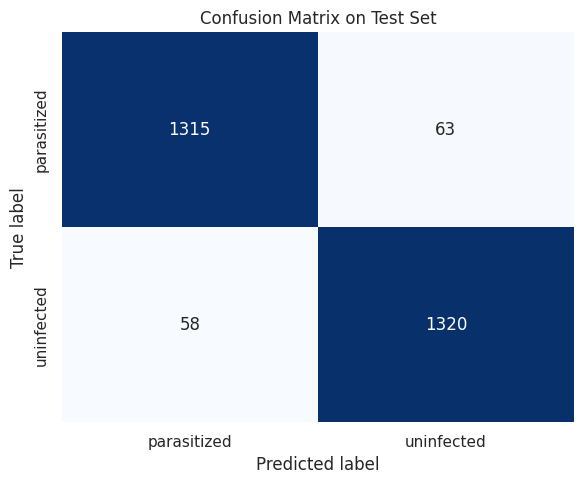

,predicted_parasitized,predicted_uninfected
actual_parasitized,1315,63
actual_uninfected,58,1320


In [11]:
cm = confusion_matrix(y_true, y_pred, labels=[parasitized_index, uninfected_index])

cm_df = pd.DataFrame(
    cm,
    index=["actual_parasitized", "actual_uninfected"],
    columns=["predicted_parasitized", "predicted_uninfected"],
)
cm_df.to_csv(OUTPUT_DIR / "confusion_matrix.csv")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["parasitized", "uninfected"],
    yticklabels=["parasitized", "uninfected"],
    cbar=False,
)
plt.title("Confusion Matrix on Test Set")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300)
plt.show()

cm_df

## 10. ROC Curve

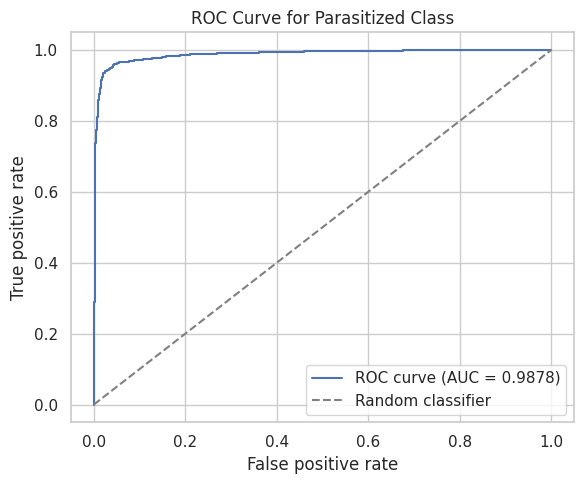

ROC-AUC for parasitized class: 0.9878


In [12]:
plt.figure(figsize=(6, 5))
plt.plot(roc_fpr, roc_tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.title("ROC Curve for Parasitized Class")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_parasitized.png", dpi=300)
plt.show()

print(f"ROC-AUC for parasitized class: {roc_auc:.4f}")

## 11. Misclassified Examples

In [13]:
false_negative = predictions[
    (predictions["true_label"] == "parasitized")
    & (predictions["predicted_label"] == "uninfected")
].head(4)

false_positive = predictions[
    (predictions["true_label"] == "uninfected")
    & (predictions["predicted_label"] == "parasitized")
].head(4)

misclassified_examples = pd.concat([false_negative, false_positive], ignore_index=True)
misclassified_examples

,relative_path,true_label,predicted_label,uninfected_probability,parasitized_probability,correct
0,parasitized/C101P62ThinF_IMG_20150923_165215_c...,parasitized,uninfected,0.546797,0.453203,False
1,parasitized/C102P63ThinF_IMG_20150918_162300_c...,parasitized,uninfected,0.755981,0.244019,False
2,parasitized/C115P76ThinF_IMG_20150930_161825_c...,parasitized,uninfected,0.937023,0.062977,False
3,parasitized/C115P76ThinF_IMG_20150930_162038_c...,parasitized,uninfected,0.523916,0.476084,False
4,uninfected/C115P76ThinF_IMG_20150930_163018_ce...,uninfected,parasitized,0.107190,0.892810,False
5,uninfected/C117P78ThinF_IMG_20150930_214511_ce...,uninfected,parasitized,0.030269,0.969731,False
6,uninfected/C117P78ThinF_IMG_20150930_221812_ce...,uninfected,parasitized,0.119935,0.880065,False
7,uninfected/C118P79ThinF_IMG_20151002_110725_ce...,uninfected,parasitized,0.499625,0.500375,False


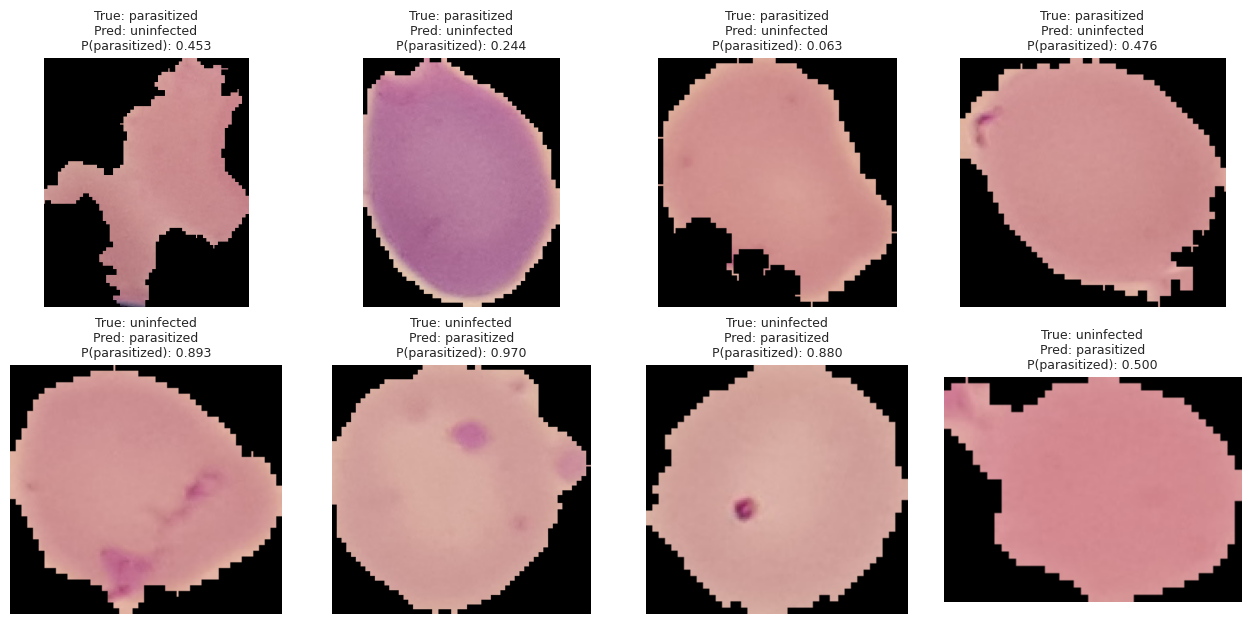

In [14]:
if misclassified_examples.empty:
    print("No misclassified examples were found on the test set.")
else:
    cols = 4
    rows = int(np.ceil(len(misclassified_examples) / cols))
    plt.figure(figsize=(cols * 3.2, rows * 3.2))

    for index, row in misclassified_examples.iterrows():
        image_path = TEST_DIR / row["relative_path"]
        image = plt.imread(image_path)
        ax = plt.subplot(rows, cols, index + 1)
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Pred: {row['predicted_label']}\n"
            f"P(parasitized): {row['parasitized_probability']:.3f}",
            fontsize=9,
        )

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "misclassified_examples.png", dpi=300)
    plt.show()